In [10]:
import polars as pl
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from deep_hedging.results import load_runs

In [2]:
df = load_runs(Path("../runs"), "entropic_tc_c*_seed*")
print(df)

shape: (15, 14)
┌───────────┬──────────┬───────────────┬──────────┬───┬──────────┬──────────────┬────────┬──────┐
│ pnl_mean  ┆ pnl_std  ┆ entropic_risk ┆ var      ┆ … ┆ bs_cvar  ┆ bs_mean_cost ┆ c      ┆ seed │
│ ---       ┆ ---      ┆ ---           ┆ ---      ┆   ┆ ---      ┆ ---          ┆ ---    ┆ ---  │
│ f64       ┆ f64      ┆ f64           ┆ f64      ┆   ┆ f64      ┆ f64          ┆ f64    ┆ i64  │
╞═══════════╪══════════╪═══════════════╪══════════╪═══╪══════════╪══════════════╪════════╪══════╡
│ -2.404049 ┆ 0.412085 ┆ 2.489543      ┆ 2.415435 ┆ … ┆ 2.698767 ┆ 0.136736     ┆ 0.0005 ┆ 0    │
│ -2.404351 ┆ 0.411669 ┆ 2.488992      ┆ 2.418272 ┆ … ┆ 2.698767 ┆ 0.136736     ┆ 0.0005 ┆ 1    │
│ -2.403067 ┆ 0.407884 ┆ 2.486505      ┆ 2.416273 ┆ … ┆ 2.698767 ┆ 0.136736     ┆ 0.0005 ┆ 2    │
│ -2.501129 ┆ 0.44905  ┆ 2.602384      ┆ 2.51742  ┆ … ┆ 2.843997 ┆ 0.273472     ┆ 0.001  ┆ 0    │
│ -2.499793 ┆ 0.446839 ┆ 2.599993      ┆ 2.513035 ┆ … ┆ 2.843997 ┆ 0.273472     ┆ 0.001  ┆ 1    │
│ … 

In [ ]:
stats = (
    df.group_by("c")
      .agg(
          pl.col("entropic_risk").mean().alias("MEAN_entropic_risk"),
          pl.col("entropic_risk").std().alias("STD_entropic_risk"),
          pl.col("bs_entropic_risk").mean().alias("MEAN_bs_entropic_risk"),
          pl.col("mean_cost").mean().alias("MEAN_mean_cost"),
          pl.col("bs_mean_cost").mean().alias("MEAN_bs_mean_cost"),
      )
)
stats = stats.sort("c")
print(stats)

shape: (5, 6)
┌────────┬──────────────────┬─────────────────┬─────────────────┬────────────────┬─────────────────┐
│ c      ┆ MEAN_entropic_ri ┆ STD_entropic_ri ┆ MEAN_bs_entropi ┆ MEAN_mean_cost ┆ MEAN_bs_mean_co │
│ ---    ┆ sk               ┆ sk              ┆ c_risk          ┆ ---            ┆ st              │
│ f64    ┆ ---              ┆ ---             ┆ ---             ┆ f64            ┆ ---             │
│        ┆ f64              ┆ f64             ┆ f64             ┆                ┆ f64             │
╞════════╪══════════════════╪═════════════════╪═════════════════╪════════════════╪═════════════════╡
│ 0.0    ┆ 2.363049         ┆ 0.001071        ┆ 2.355081        ┆ 0.0            ┆ 0.0             │
│ 0.0005 ┆ 2.488346         ┆ 0.001619        ┆ 2.495824        ┆ 0.115743       ┆ 0.136736        │
│ 0.001  ┆ 2.600351         ┆ 0.001879        ┆ 2.638223        ┆ 0.21203        ┆ 0.273472        │
│ 0.005  ┆ 3.334697         ┆ 0.010768        ┆ 3.835708        ┆ 0.804708   

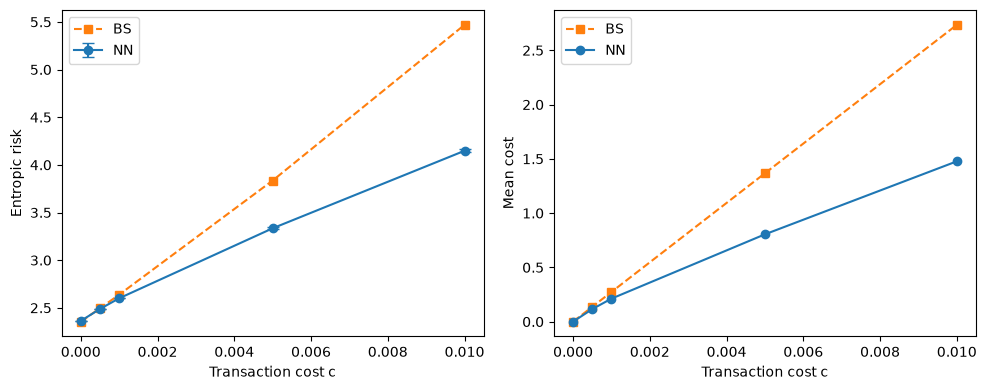

In [27]:
c_values = stats["c"].to_numpy()

x = c_values

y_nn = stats["MEAN_entropic_risk"].to_numpy()
yerr_nn = stats["STD_entropic_risk"].to_numpy()

y_bs = stats["MEAN_bs_entropic_risk"].to_numpy()

y_cost_nn = stats["MEAN_mean_cost"].to_numpy()
y_cost_bs = stats["MEAN_bs_mean_cost"].to_numpy()

fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(10, 4))

ax1.errorbar(x, y_nn, yerr=yerr_nn, marker="o", capsize=4, label="NN")
ax1.plot(x, y_bs, marker="s", linestyle="--", label="BS")
ax1.set_xlabel("Transaction cost c")
ax1.set_ylabel("Entropic risk")
ax1.legend()

ax2.errorbar(x, y_cost_nn, marker="o", capsize=4, label="NN")
ax2.plot(x, y_cost_bs, marker="s", linestyle="--", label="BS")
ax2.set_xlabel("Transaction cost c")
ax2.set_ylabel("Mean cost")
ax2.legend()

fig.tight_layout()


In [28]:
Path("results/transaction_cost_plots").mkdir(exist_ok=True)
fig.savefig("results/transaction_cost_plots/nn_vs_bs_entropic_risk_mean_cost.png", dpi=150, bbox_inches="tight")


Slope: 0.8843, Intercept: 4.6556
Ref Slope: 0.6667, Ref Intercept: 3.3275


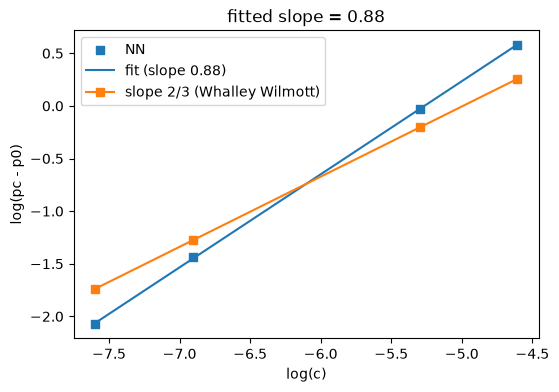

In [40]:
p0 = stats.filter(pl.col("c") == 0)["MEAN_entropic_risk"].to_numpy()
pc = stats.filter(pl.col("c") > 0)["MEAN_entropic_risk"].to_numpy()

dp = pc - p0

x = np.log(c_values[c_values > 0])
y = np.log(dp)

slope, intercept = np.polyfit(x, y, 1)
y_fit = slope * x + intercept
print(f"Slope: {slope:.4f}, Intercept: {intercept:.4f}")

b = y.mean() - (2/3) * x.mean()
y_ref = (2/3) * x + b
print(f"Ref Slope: {2/3:.4f}, Ref Intercept: {b:.4f}")


fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.scatter(x, y, marker="s", label="NN")
ax1.plot(x, y_fit, linestyle="-", label=f"fit (slope {slope:.2f})")
ax1.plot(x, y_ref, marker="s", linestyle="-", label="slope 2/3 (Whalley Wilmott)")
ax1.set_xlabel("log(c)")
ax1.set_ylabel("log(pc - p0)")
ax1.set_title(f"fitted slope = {slope:.2f}")
ax1.legend()

fig.savefig("results/transaction_cost_plots/price_asymptotics.png", dpi=150, bbox_inches="tight")